In [1]:
!pip -q install datasets[audio] librosa soundfile

from datasets import load_dataset

print("Downloading/loading DFADD...")
dfadd = load_dataset(
    "SpeechAntiSpoofingBenchmarks/DFADD",
    split="test"
)

print("\nDataset loaded successfully!")
print(dfadd)

Downloading/loading DFADD...


README.md:   0%|          | 0.00/3.70k [00:00<?, ?B/s]

data/test-00000-of-00002.parquet: reconstructing file:   0%|          |  0.00B /  302MB            

data/test-00000-of-00002.parquet: downloading bytes:           |  0.00B            

data/test-00001-of-00002.parquet: reconstructing file:   0%|          |  0.00B /  239MB            

data/test-00001-of-00002.parquet: downloading bytes:           |  0.00B            

Generating test split:   0%|          | 0/3755 [00:00<?, ? examples/s]


Dataset loaded successfully!
Dataset({
    features: ['path', 'audio', 'label', 'notes'],
    num_rows: 3755
})


In [2]:
print("Number of samples:", len(dfadd))

print("\nColumns:")
print(dfadd.column_names)

print("\nFirst sample:")
print(dfadd[0])

Number of samples: 3755

Columns:
['path', 'audio', 'label', 'notes']

First sample:
{'path': 'DATASET_GradTTS/test/p227_001_GradTTS.flac', 'audio': <datasets.features._torchcodec.AudioDecoder object at 0x79b0669030e0>, 'label': 1, 'notes': '{"utterance_id": "gradtts__p227_001_GradTTS", "generator": "gradtts", "speaker": "p227", "attack": "gradtts"}'}


In [3]:
from collections import Counter

print(Counter(dfadd["label"]))

Counter({1: 3000, 0: 755})


In [4]:
# ==========================================
# CELL 4: CREATE BALANCED DATASET
# ==========================================

from datasets import concatenate_datasets
from collections import Counter
import numpy as np

# Separate Bonafide and Spoof
bonafide = dfadd.filter(lambda x: x["label"] == 0)
spoof = dfadd.filter(lambda x: x["label"] == 1)

print("Bonafide samples:", len(bonafide))
print("Spoof samples:", len(spoof))

# Select the same number of Spoof samples as Bonafide
np.random.seed(42)

spoof = spoof.shuffle(seed=42).select(
    range(len(bonafide))
)

# Combine both datasets
balanced_dataset = concatenate_datasets([
    bonafide,
    spoof
])

# Shuffle the combined dataset
balanced_dataset = balanced_dataset.shuffle(seed=42)

# Check result
print("\n✅ Balanced dataset created!")
print("Total samples:", len(balanced_dataset))
print("Class distribution:", Counter(balanced_dataset["label"]))

Filter:   0%|          | 0/3755 [00:00<?, ? examples/s]

Filter:   0%|          | 0/3755 [00:00<?, ? examples/s]

Bonafide samples: 755
Spoof samples: 3000

✅ Balanced dataset created!
Total samples: 1510
Class distribution: Counter({0: 755, 1: 755})


In [5]:
# ==========================================
# CELL 5: AUDIO FEATURE EXTRACTION
# ==========================================

import librosa
import numpy as np
from tqdm.auto import tqdm

def extract_features(audio_data, sr=16000):
    """
    Extract numerical speech features from an audio clip.

    Features:
    - 40 MFCC mean
    - 40 MFCC standard deviation
    - Zero Crossing Rate
    - Spectral Centroid
    - Spectral Bandwidth
    - RMS Energy
    """

    # Get audio samples
    signal = np.asarray(audio_data, dtype=np.float32)

    # Make sure audio is not empty
    if len(signal) == 0:
        return None

    # Normalize audio
    signal = signal / (np.max(np.abs(signal)) + 1e-8)

    # MFCC features
    mfcc = librosa.feature.mfcc(
        y=signal,
        sr=sr,
        n_mfcc=40
    )

    # Mean and standard deviation of MFCCs
    mfcc_mean = np.mean(mfcc, axis=1)
    mfcc_std = np.std(mfcc, axis=1)

    # Other audio features
    zcr = np.mean(
        librosa.feature.zero_crossing_rate(signal)
    )

    spectral_centroid = np.mean(
        librosa.feature.spectral_centroid(
            y=signal,
            sr=sr
        )
    )

    spectral_bandwidth = np.mean(
        librosa.feature.spectral_bandwidth(
            y=signal,
            sr=sr
        )
    )

    rms = np.mean(
        librosa.feature.rms(y=signal)
    )

    # Combine all features
    features = np.concatenate([
        mfcc_mean,
        mfcc_std,
        [zcr],
        [spectral_centroid],
        [spectral_bandwidth],
        [rms]
    ])

    return features


# ==========================================
# EXTRACT FEATURES FROM ALL 1510 AUDIO FILES
# ==========================================

X_features = []
y_labels = []

failed = 0

print("Extracting audio features...")
print("This may take a few minutes...\n")

for i in tqdm(range(len(balanced_dataset))):

    try:
        audio = balanced_dataset[i]["audio"]

        features = extract_features(
            audio["array"],
            audio["sampling_rate"]
        )

        if features is not None:
            X_features.append(features)
            y_labels.append(
                balanced_dataset[i]["label"]
            )

    except Exception as e:
        failed += 1
        print(f"Skipped sample {i}: {e}")


# Convert to NumPy arrays
X_features = np.array(X_features, dtype=np.float32)
y_labels = np.array(y_labels, dtype=np.int32)

print("\n====================================")
print("FEATURE EXTRACTION COMPLETED")
print("====================================")

print("Feature matrix shape:", X_features.shape)
print("Labels shape:", y_labels.shape)
print("Failed files:", failed)

print("\nNumber of features per audio:",
      X_features.shape[1])

print("\nFirst 5 labels:")
print(y_labels[:5])

print("\nFeature example:")
print(X_features[0][:10])

Extracting audio features...
This may take a few minutes...



  0%|          | 0/1510 [00:00<?, ?it/s]


FEATURE EXTRACTION COMPLETED
Feature matrix shape: (1510, 84)
Labels shape: (1510,)
Failed files: 0

Number of features per audio: 84

First 5 labels:
[0 0 1 0 1]

Feature example:
[-314.95526     80.341934    11.297795    28.140337    -0.9550579
   18.418497     1.3611269   -1.9077579   -2.3106022    2.4956589]


In [6]:
# ==========================================
# CELL 6: TRAIN / VALIDATION / TEST SPLIT
# ==========================================

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

# Split into training (70%) and temporary data (30%)
X_train, X_temp, y_train, y_temp = train_test_split(
    X_features,
    y_labels,
    test_size=0.30,
    stratify=y_labels,
    random_state=42
)

# Split temporary data into validation (15%) and test (15%)
X_val, X_test, y_val, y_test = train_test_split(
    X_temp,
    y_temp,
    test_size=0.50,
    stratify=y_temp,
    random_state=42
)

# ==========================================
# FEATURE SCALING
# ==========================================

scaler = StandardScaler()

# Fit ONLY on training data
X_train = scaler.fit_transform(X_train)

# Apply same scaling to validation and test
X_val = scaler.transform(X_val)
X_test = scaler.transform(X_test)

# ==========================================
# CHECK RESULTS
# ==========================================

print("======================================")
print("DATA SPLIT COMPLETED")
print("======================================")

print("Training samples :", X_train.shape[0])
print("Validation samples:", X_val.shape[0])
print("Testing samples  :", X_test.shape[0])

print("\nFeatures per sample:", X_train.shape[1])

print("\nFinal shapes:")
print("X_train:", X_train.shape)
print("X_val  :", X_val.shape)
print("X_test :", X_test.shape)

print("\nClass distribution:")
print("Training - Bonafide:", sum(y_train == 0))
print("Training - Spoof   :", sum(y_train == 1))
print("Testing  - Bonafide:", sum(y_test == 0))
print("Testing  - Spoof   :", sum(y_test == 1))

DATA SPLIT COMPLETED
Training samples : 1057
Validation samples: 226
Testing samples  : 227

Features per sample: 84

Final shapes:
X_train: (1057, 84)
X_val  : (226, 84)
X_test : (227, 84)

Class distribution:
Training - Bonafide: 528
Training - Spoof   : 529
Testing  - Bonafide: 114
Testing  - Spoof   : 113


In [7]:
# ==========================================
# CELL 7: ANN - ACTIVATION FUNCTION COMPARISON
# ==========================================

import tensorflow as tf
import numpy as np

# Reproducibility
np.random.seed(42)
tf.random.set_seed(42)

# ------------------------------------------
# ANN MODEL FUNCTION
# ------------------------------------------

def build_ann(activation):

    model = tf.keras.Sequential([

        # Input layer: 84 audio features
        tf.keras.layers.Input(shape=(84,)),

        # Hidden Layer 1
        tf.keras.layers.Dense(
            64,
            activation=activation
        ),

        # Dropout: 20%
        tf.keras.layers.Dropout(0.20),

        # Hidden Layer 2
        tf.keras.layers.Dense(
            32,
            activation=activation
        ),

        # Output Layer
        # 0 = Bonafide
        # 1 = Spoof
        tf.keras.layers.Dense(
            1,
            activation="sigmoid"
        )
    ])

    # Compile model
    model.compile(
        optimizer=tf.keras.optimizers.Adam(
            learning_rate=0.001
        ),
        loss="binary_crossentropy",
        metrics=["accuracy"]
    )

    return model


# ------------------------------------------
# TRAIN 3 ANN MODELS
# ------------------------------------------

activations = ["relu", "tanh", "sigmoid"]

models = {}
histories = {}

for activation in activations:

    print("\n" + "=" * 60)
    print(f"TRAINING ANN WITH {activation.upper()} ACTIVATION")
    print("=" * 60)

    tf.random.set_seed(42)

    model = build_ann(activation)

    early_stopping = tf.keras.callbacks.EarlyStopping(
        monitor="val_loss",
        patience=4,
        restore_best_weights=True
    )

    history = model.fit(
        X_train,
        y_train,

        validation_data=(
            X_val,
            y_val
        ),

        epochs=20,
        batch_size=32,

        callbacks=[
            early_stopping
        ],

        verbose=1
    )

    models[activation] = model
    histories[activation] = history


print("\n" + "=" * 60)
print("✅ ALL THREE ANN MODELS TRAINED")
print("=" * 60)


TRAINING ANN WITH RELU ACTIVATION
Epoch 1/20
34/34 ━━━━━━━━━━━━━━━━━━━━ 2s 19ms/step - accuracy: 0.7871 - loss: 0.4549 - val_accuracy: 0.8363 - val_loss: 0.3269
Epoch 2/20
34/34 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step - accuracy: 0.8950 - loss: 0.2574 - val_accuracy: 0.8938 - val_loss: 0.2316
Epoch 3/20
34/34 ━━━━━━━━━━━━━━━━━━━━ 1s 11ms/step - accuracy: 0.9461 - loss: 0.1660 - val_accuracy: 0.9336 - val_loss: 0.1551
Epoch 4/20
34/34 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - accuracy: 0.9631 - loss: 0.1123 - val_accuracy: 0.9646 - val_loss: 0.1065
Epoch 5/20
34/34 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - accuracy: 0.9773 - loss: 0.0733 - val_accuracy: 0.9690 - val_loss: 0.0787
Epoch 6/20
34/34 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - accuracy: 0.9868 - loss: 0.0537 - val_accuracy: 0.9690 - val_loss: 0.0621
Epoch 7/20
34/34 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - accuracy: 0.9896 - loss: 0.0358 - val_accuracy: 0.9779 - val_loss: 0.0511
Epoch 8/20
34/34 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - accuracy: 0.9915 - loss: 0.03

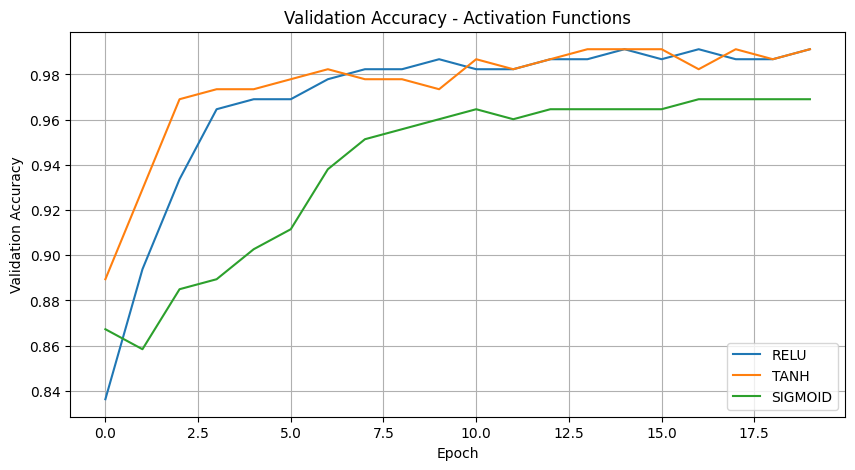

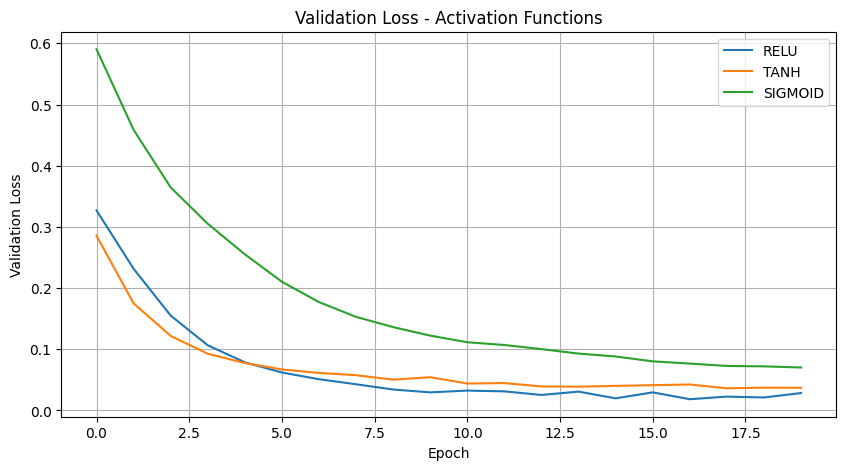

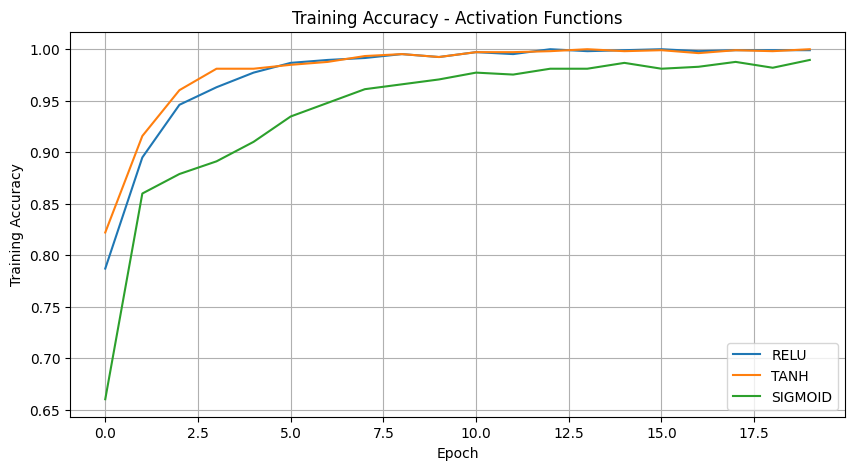

In [8]:
# ==========================================
# CELL 8: TRAINING PERFORMANCE COMPARISON
# ==========================================

import matplotlib.pyplot as plt

# ------------------------------------------
# VALIDATION ACCURACY
# ------------------------------------------

plt.figure(figsize=(10, 5))

for activation in activations:
    plt.plot(
        histories[activation].history["val_accuracy"],
        label=activation.upper()
    )

plt.title("Validation Accuracy - Activation Functions")
plt.xlabel("Epoch")
plt.ylabel("Validation Accuracy")
plt.legend()
plt.grid(True)
plt.show()


# ------------------------------------------
# VALIDATION LOSS
# ------------------------------------------

plt.figure(figsize=(10, 5))

for activation in activations:
    plt.plot(
        histories[activation].history["val_loss"],
        label=activation.upper()
    )

plt.title("Validation Loss - Activation Functions")
plt.xlabel("Epoch")
plt.ylabel("Validation Loss")
plt.legend()
plt.grid(True)
plt.show()


# ------------------------------------------
# TRAINING ACCURACY
# ------------------------------------------

plt.figure(figsize=(10, 5))

for activation in activations:
    plt.plot(
        histories[activation].history["accuracy"],
        label=activation.upper()
    )

plt.title("Training Accuracy - Activation Functions")
plt.xlabel("Epoch")
plt.ylabel("Training Accuracy")
plt.legend()
plt.grid(True)
plt.show()

In [9]:
# ==========================================
# CELL 9: FINAL MODEL EVALUATION
# ==========================================

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score
)
import pandas as pd

results = []

for activation in activations:

    model = models[activation]

    # Get probability of Spoof
    probabilities = model.predict(
        X_test,
        verbose=0
    ).ravel()

    # Convert probability to class
    predictions = (
        probabilities >= 0.5
    ).astype(int)

    # Calculate metrics
    results.append({
        "Activation": activation.upper(),
        "Accuracy": accuracy_score(
            y_test, predictions
        ),
        "Precision": precision_score(
            y_test, predictions
        ),
        "Recall": recall_score(
            y_test, predictions
        ),
        "F1 Score": f1_score(
            y_test, predictions
        ),
        "ROC-AUC": roc_auc_score(
            y_test, probabilities
        )
    })


# Create comparison table
results_df = pd.DataFrame(results)

print("=" * 70)
print("FINAL ANN PERFORMANCE COMPARISON")
print("=" * 70)

display(
    results_df.style.format({
        "Accuracy": "{:.4f}",
        "Precision": "{:.4f}",
        "Recall": "{:.4f}",
        "F1 Score": "{:.4f}",
        "ROC-AUC": "{:.4f}"
    })
)

# ------------------------------------------
# FIND BEST MODEL
# ------------------------------------------

best_index = results_df["F1 Score"].idxmax()

best_activation = results_df.loc[
    best_index, "Activation"
].lower()

print("\n🏆 BEST ACTIVATION FUNCTION:",
      best_activation.upper())

print(
    "Best F1 Score:",
    round(
        results_df.loc[best_index, "F1 Score"],
        4
    )
)

FINAL ANN PERFORMANCE COMPARISON


,Activation,Accuracy,Precision,Recall,F1 Score,ROC-AUC
0,RELU,1.0000,1.0000,1.0000,1.0000,1.0000
1,TANH,0.9956,1.0000,0.9912,0.9956,0.9999
2,SIGMOID,0.9956,0.9912,1.0000,0.9956,0.9999



🏆 BEST ACTIVATION FUNCTION: RELU
Best F1 Score: 1.0


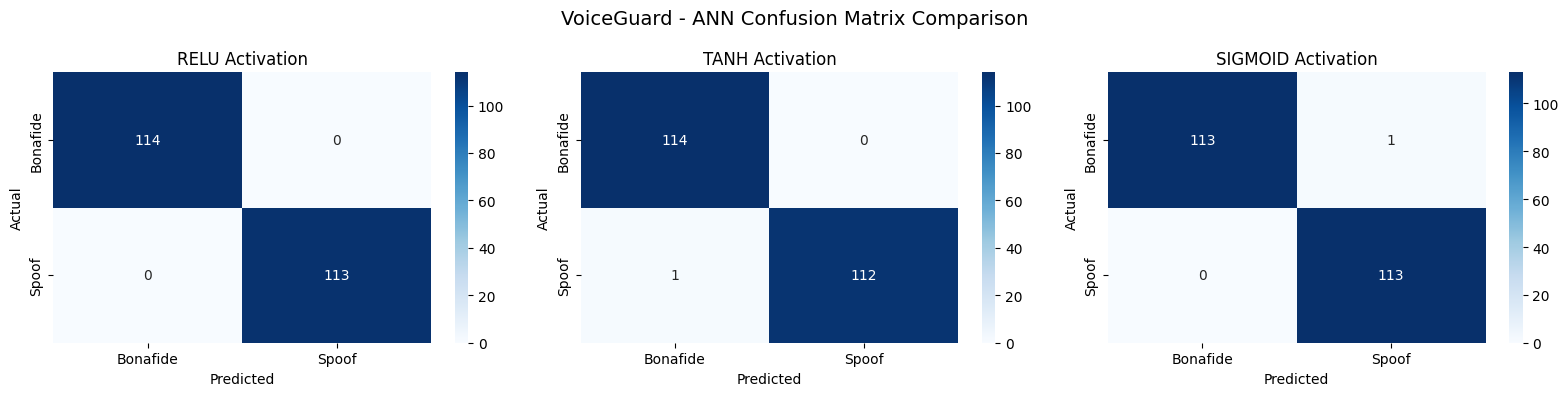

In [10]:
# ==========================================
# CELL 10: CONFUSION MATRICES
# ==========================================

from sklearn.metrics import confusion_matrix
import seaborn as sns
import matplotlib.pyplot as plt

fig, axes = plt.subplots(
    1, 3,
    figsize=(16, 4)
)

for ax, activation in zip(axes, activations):

    model = models[activation]

    # Predictions
    probabilities = model.predict(
        X_test,
        verbose=0
    ).ravel()

    predictions = (
        probabilities >= 0.5
    ).astype(int)

    # Confusion matrix
    cm = confusion_matrix(
        y_test,
        predictions
    )

    # Plot
    sns.heatmap(
        cm,
        annot=True,
        fmt="d",
        cmap="Blues",
        ax=ax,
        xticklabels=["Bonafide", "Spoof"],
        yticklabels=["Bonafide", "Spoof"]
    )

    ax.set_title(
        f"{activation.upper()} Activation"
    )

    ax.set_xlabel("Predicted")
    ax.set_ylabel("Actual")


plt.suptitle(
    "VoiceGuard - ANN Confusion Matrix Comparison",
    fontsize=14
)

plt.tight_layout()
plt.show()

In [11]:
# ==========================================
# CELL 11: BEST MODEL REPORT + SAVE
# ==========================================

from sklearn.metrics import classification_report

# Get the best model
best_model = models[best_activation]

# Predict on test data
best_probabilities = best_model.predict(
    X_test,
    verbose=0
).ravel()

best_predictions = (
    best_probabilities >= 0.5
).astype(int)

# Classification report
print("=" * 70)
print(f"VOICEGUARD - BEST ANN: {best_activation.upper()}")
print("=" * 70)

print(
    classification_report(
        y_test,
        best_predictions,
        target_names=[
            "Bonafide",
            "Spoof"
        ]
    )
)

# Save best model
model_path = "/content/VoiceGuard_ANN_best.keras"

best_model.save(model_path)

print("\n" + "=" * 70)
print("BEST MODEL SAVED")
print("=" * 70)

print("Location:", model_path)
print("Activation:", best_activation.upper())

# Show model architecture
print("\nANN Architecture:")
best_model.summary()

VOICEGUARD - BEST ANN: RELU
              precision    recall  f1-score   support

    Bonafide       1.00      1.00      1.00       114
       Spoof       1.00      1.00      1.00       113

    accuracy                           1.00       227
   macro avg       1.00      1.00      1.00       227
weighted avg       1.00      1.00      1.00       227


BEST MODEL SAVED
Location: /content/VoiceGuard_ANN_best.keras
Activation: RELU

ANN Architecture:


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 64)             │         5,440 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 1)              │            33 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 22,661 (88.52 KB)

 Trainable params: 7,553 (29.50 KB)

 Non-trainable params: 0 (0.00 B)

 Optimizer params: 15,108 (59.02 KB)

In [12]:
# Save VoiceGuard trained model

best_model.save("/content/VoiceGuard_ANN_best.keras")

print("✅ Best ANN model saved successfully!")
print("File: /content/VoiceGuard_ANN_best.keras")

✅ Best ANN model saved successfully!
File: /content/VoiceGuard_ANN_best.keras


In [13]:
import numpy as np

# Save extracted features and labels
np.savez(
    "/content/VoiceGuard_features.npz",
    X_features=X_features,
    y_labels=y_labels
)

print("✅ Features and labels saved successfully!")
print("File: /content/VoiceGuard_features.npz")
print("Features shape:", X_features.shape)
print("Labels shape:", y_labels.shape)

✅ Features and labels saved successfully!
File: /content/VoiceGuard_features.npz
Features shape: (1510, 84)
Labels shape: (1510,)


In [14]:
import joblib

# Save the StandardScaler
joblib.dump(scaler, "/content/VoiceGuard_scaler.pkl")

print("✅ Scaler saved successfully!")
print("File: /content/VoiceGuard_scaler.pkl")

✅ Scaler saved successfully!
File: /content/VoiceGuard_scaler.pkl


In [15]:
# Save VoiceGuard model comparison results

results_df.to_csv(
    "/content/VoiceGuard_model_results.csv",
    index=False
)

print("✅ Model results saved successfully!")
print("File: /content/VoiceGuard_model_results.csv")

display(results_df)

✅ Model results saved successfully!
File: /content/VoiceGuard_model_results.csv


,Activation,Accuracy,Precision,Recall,F1 Score,ROC-AUC
0,RELU,1.000000,1.000000,1.00000,1.000000,1.000000
1,TANH,0.995595,1.000000,0.99115,0.995556,0.999922
2,SIGMOID,0.995595,0.991228,1.00000,0.995595,0.999922


In [16]:
!pip -q install keras-tuner

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 129.4/129.4 kB 2.6 MB/s eta 0:00:00


In [17]:
import tensorflow as tf
import keras_tuner as kt
import numpy as np

np.random.seed(42)
tf.random.set_seed(42)

print("✅ Libraries imported successfully!")
print("TensorFlow version:", tf.__version__)
print("Keras Tuner version:", kt.__version__)

✅ Libraries imported successfully!
TensorFlow version: 2.20.0
Keras Tuner version: 1.4.8


In [18]:
def build_tuned_ann(hp):

    model = tf.keras.Sequential([
        tf.keras.layers.Input(shape=(84,)),

        tf.keras.layers.Dense(
            units=hp.Choice(
                "units_1",
                values=[32, 64, 128]
            ),
            activation="relu"
        ),

        tf.keras.layers.Dropout(
            rate=hp.Choice(
                "dropout",
                values=[0.0, 0.2, 0.3]
            )
        ),

        tf.keras.layers.Dense(
            units=hp.Choice(
                "units_2",
                values=[16, 32, 64]
            ),
            activation="relu"
        ),

        tf.keras.layers.Dense(
            1,
            activation="sigmoid"
        )
    ])

    learning_rate = hp.Choice(
        "learning_rate",
        values=[0.001, 0.0005]
    )

    model.compile(
        optimizer=tf.keras.optimizers.Adam(
            learning_rate=learning_rate
        ),
        loss="binary_crossentropy",
        metrics=["accuracy"]
    )

    return model


print("✅ Hyperparameter model created!")

✅ Hyperparameter model created!


In [20]:
tuner = kt.RandomSearch(
    build_tuned_ann,
    objective="val_loss",
    max_trials=20,
    executions_per_trial=1,
    directory="/content/voiceguard_tuning",
    project_name="ann_hyperparameter_tuning",
    overwrite=True
)

print("✅ Hyperparameter tuner created!")

tuner.search_space_summary()

✅ Hyperparameter tuner created!
Search space summary
Default search space size: 4
units_1 (Choice)
{'default': 32, 'conditions': [], 'values': [32, 64, 128], 'ordered': True}
dropout (Choice)
{'default': 0.0, 'conditions': [], 'values': [0.0, 0.2, 0.3], 'ordered': True}
units_2 (Choice)
{'default': 16, 'conditions': [], 'values': [16, 32, 64], 'ordered': True}
learning_rate (Choice)
{'default': 0.001, 'conditions': [], 'values': [0.001, 0.0005], 'ordered': True}


In [21]:
print("=" * 70)
print("VOICEGUARD - HYPERPARAMETER TUNING")
print("=" * 70)

tuner.search(
    X_train,
    y_train,
    validation_data=(X_val, y_val),
    epochs=20,
    batch_size=32,
    verbose=1
)

print("\n" + "=" * 70)
print("✅ HYPERPARAMETER TUNING COMPLETED")
print("=" * 70)

Trial 20 Complete [00h 00m 08s]
val_loss: 0.017513461410999298

Best val_loss So Far: 0.010883944109082222
Total elapsed time: 00h 02m 51s

✅ HYPERPARAMETER TUNING COMPLETED


In [22]:
best_hps = tuner.get_best_hyperparameters(num_trials=1)[0]

print("=" * 70)
print("BEST HYPERPARAMETERS")
print("=" * 70)

print("Layer 1 neurons :", best_hps.get("units_1"))
print("Layer 2 neurons :", best_hps.get("units_2"))
print("Dropout rate    :", best_hps.get("dropout"))
print("Learning rate   :", best_hps.get("learning_rate"))

BEST HYPERPARAMETERS
Layer 1 neurons : 128
Layer 2 neurons : 64
Dropout rate    : 0.3
Learning rate   : 0.001


In [23]:
best_tuned_model = tuner.get_best_models(num_models=1)[0]

print("✅ Best tuned ANN model retrieved!")

print("\nArchitecture:")
best_tuned_model.summary()

✅ Best tuned ANN model retrieved!

Architecture:


/usr/local/lib/python3.13/dist-packages/keras/src/saving/saving_lib.py:797: UserWarning: Skipping variable loading for optimizer 'adam', because it has 2 variables whereas the saved optimizer has 14 variables. 
  saveable.load_own_variables(weights_store.get(inner_path))


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 128)            │        10,880 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 1)              │            65 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 19,201 (75.00 KB)

 Trainable params: 19,201 (75.00 KB)

 Non-trainable params: 0 (0.00 B)

In [24]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score
)

tuned_probabilities = best_tuned_model.predict(
    X_test,
    verbose=0
).ravel()

tuned_predictions = (
    tuned_probabilities >= 0.5
).astype(int)

tuned_results = {
    "Model": "Tuned ANN",
    "Accuracy": accuracy_score(y_test, tuned_predictions),
    "Precision": precision_score(y_test, tuned_predictions),
    "Recall": recall_score(y_test, tuned_predictions),
    "F1 Score": f1_score(y_test, tuned_predictions),
    "ROC-AUC": roc_auc_score(y_test, tuned_probabilities)
}

print("=" * 70)
print("VOICEGUARD - TUNED ANN TEST PERFORMANCE")
print("=" * 70)

for metric, value in tuned_results.items():
    if metric == "Model":
        print(f"{metric}: {value}")
    else:
        print(f"{metric}: {value:.4f}")

VOICEGUARD - TUNED ANN TEST PERFORMANCE
Model: Tuned ANN
Accuracy: 1.0000
Precision: 1.0000
Recall: 1.0000
F1 Score: 1.0000
ROC-AUC: 1.0000


In [25]:
original_best_row = results_df.loc[
    results_df["F1 Score"].idxmax()
]

comparison_df = pd.DataFrame([
    {
        "Model": f"Original ANN ({original_best_row['Activation']})",
        "Accuracy": original_best_row["Accuracy"],
        "Precision": original_best_row["Precision"],
        "Recall": original_best_row["Recall"],
        "F1 Score": original_best_row["F1 Score"],
        "ROC-AUC": original_best_row["ROC-AUC"]
    },
    tuned_results
])

print("=" * 70)
print("ORIGINAL ANN vs TUNED ANN")
print("=" * 70)

display(
    comparison_df.style.format({
        "Accuracy": "{:.4f}",
        "Precision": "{:.4f}",
        "Recall": "{:.4f}",
        "F1 Score": "{:.4f}",
        "ROC-AUC": "{:.4f}"
    })
)

ORIGINAL ANN vs TUNED ANN


,Model,Accuracy,Precision,Recall,F1 Score,ROC-AUC
0,Original ANN (RELU),1.0000,1.0000,1.0000,1.0000,1.0000
1,Tuned ANN,1.0000,1.0000,1.0000,1.0000,1.0000


In [26]:
comparison_df.to_csv(
    "/content/VoiceGuard_tuning_comparison.csv",
    index=False
)

print("✅ Tuning comparison saved!")
print("File: /content/VoiceGuard_tuning_comparison.csv")

✅ Tuning comparison saved!
File: /content/VoiceGuard_tuning_comparison.csv


In [27]:
import tensorflow as tf
import numpy as np

tf.random.set_seed(42)
np.random.seed(42)

# Get best hyperparameters from tuning
best_units_1 = best_hps.get("units_1")
best_units_2 = best_hps.get("units_2")
best_dropout = best_hps.get("dropout")
best_learning_rate = best_hps.get("learning_rate")

# Build model
model_without_es = tf.keras.Sequential([
    tf.keras.layers.Input(shape=(84,)),
    tf.keras.layers.Dense(
        best_units_1,
        activation="relu"
    ),
    tf.keras.layers.Dropout(best_dropout),
    tf.keras.layers.Dense(
        best_units_2,
        activation="relu"
    ),
    tf.keras.layers.Dense(
        1,
        activation="sigmoid"
    )
])

model_without_es.compile(
    optimizer=tf.keras.optimizers.Adam(
        learning_rate=best_learning_rate
    ),
    loss="binary_crossentropy",
    metrics=["accuracy"]
)

print("=" * 70)
print("TRAINING WITHOUT EARLY STOPPING")
print("=" * 70)

history_without_es = model_without_es.fit(
    X_train,
    y_train,
    validation_data=(X_val, y_val),
    epochs=20,
    batch_size=32,
    verbose=1
)

print("\n✅ Training without Early Stopping completed!")
print("Epochs trained:", len(history_without_es.history["loss"]))

TRAINING WITHOUT EARLY STOPPING
Epoch 1/20
34/34 ━━━━━━━━━━━━━━━━━━━━ 5s 28ms/step - accuracy: 0.8354 - loss: 0.3752 - val_accuracy: 0.9027 - val_loss: 0.2422
Epoch 2/20
34/34 ━━━━━━━━━━━━━━━━━━━━ 1s 22ms/step - accuracy: 0.9395 - loss: 0.1710 - val_accuracy: 0.9425 - val_loss: 0.1322
Epoch 3/20
34/34 ━━━━━━━━━━━━━━━━━━━━ 2s 30ms/step - accuracy: 0.9688 - loss: 0.0941 - val_accuracy: 0.9646 - val_loss: 0.0793
Epoch 4/20
34/34 ━━━━━━━━━━━━━━━━━━━━ 2s 54ms/step - accuracy: 0.9896 - loss: 0.0478 - val_accuracy: 0.9735 - val_loss: 0.0560
Epoch 5/20
34/34 ━━━━━━━━━━━━━━━━━━━━ 2s 33ms/step - accuracy: 0.9886 - loss: 0.0436 - val_accuracy: 0.9735 - val_loss: 0.0428
Epoch 6/20
34/34 ━━━━━━━━━━━━━━━━━━━━ 1s 21ms/step - accuracy: 0.9962 - loss: 0.0250 - val_accuracy: 0.9823 - val_loss: 0.0302
Epoch 7/20
34/34 ━━━━━━━━━━━━━━━━━━━━ 1s 28ms/step - accuracy: 0.9915 - loss: 0.0242 - val_accuracy: 0.9823 - val_loss: 0.0293
Epoch 8/20
34/34 ━━━━━━━━━━━━━━━━━━━━ 1s 23ms/step - accuracy: 0.9962 - loss: 0

In [28]:
tf.random.set_seed(42)
np.random.seed(42)

# Build the same architecture
model_with_es = tf.keras.Sequential([
    tf.keras.layers.Input(shape=(84,)),
    tf.keras.layers.Dense(
        best_units_1,
        activation="relu"
    ),
    tf.keras.layers.Dropout(best_dropout),
    tf.keras.layers.Dense(
        best_units_2,
        activation="relu"
    ),
    tf.keras.layers.Dense(
        1,
        activation="sigmoid"
    )
])

model_with_es.compile(
    optimizer=tf.keras.optimizers.Adam(
        learning_rate=best_learning_rate
    ),
    loss="binary_crossentropy",
    metrics=["accuracy"]
)

# Early stopping
early_stopping = tf.keras.callbacks.EarlyStopping(
    monitor="val_loss",
    patience=4,
    restore_best_weights=True
)

print("=" * 70)
print("TRAINING WITH EARLY STOPPING")
print("=" * 70)

history_with_es = model_with_es.fit(
    X_train,
    y_train,
    validation_data=(X_val, y_val),
    epochs=20,
    batch_size=32,
    callbacks=[early_stopping],
    verbose=1
)

print("\n✅ Training with Early Stopping completed!")
print("Epochs trained:", len(history_with_es.history["loss"]))
print("Best validation loss:",
      min(history_with_es.history["val_loss"]))

TRAINING WITH EARLY STOPPING
Epoch 1/20
34/34 ━━━━━━━━━━━━━━━━━━━━ 5s 42ms/step - accuracy: 0.8240 - loss: 0.4062 - val_accuracy: 0.8673 - val_loss: 0.2751
Epoch 2/20
34/34 ━━━━━━━━━━━━━━━━━━━━ 1s 19ms/step - accuracy: 0.9186 - loss: 0.1919 - val_accuracy: 0.9336 - val_loss: 0.1525
Epoch 3/20
34/34 ━━━━━━━━━━━━━━━━━━━━ 1s 13ms/step - accuracy: 0.9726 - loss: 0.1057 - val_accuracy: 0.9690 - val_loss: 0.0897
Epoch 4/20
34/34 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step - accuracy: 0.9830 - loss: 0.0664 - val_accuracy: 0.9823 - val_loss: 0.0581
Epoch 5/20
34/34 ━━━━━━━━━━━━━━━━━━━━ 0s 11ms/step - accuracy: 0.9839 - loss: 0.0462 - val_accuracy: 0.9867 - val_loss: 0.0401
Epoch 6/20
34/34 ━━━━━━━━━━━━━━━━━━━━ 1s 20ms/step - accuracy: 0.9905 - loss: 0.0288 - val_accuracy: 0.9823 - val_loss: 0.0359
Epoch 7/20
34/34 ━━━━━━━━━━━━━━━━━━━━ 1s 21ms/step - accuracy: 0.9981 - loss: 0.0214 - val_accuracy: 0.9867 - val_loss: 0.0314
Epoch 8/20
34/34 ━━━━━━━━━━━━━━━━━━━━ 1s 13ms/step - accuracy: 0.9934 - loss: 0.019

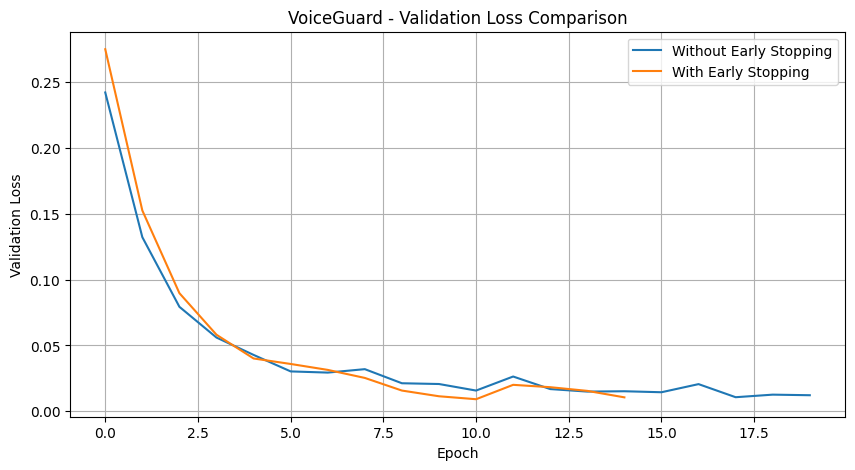

In [29]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 5))

plt.plot(
    history_without_es.history["val_loss"],
    label="Without Early Stopping"
)

plt.plot(
    history_with_es.history["val_loss"],
    label="With Early Stopping"
)

plt.title("VoiceGuard - Validation Loss Comparison")
plt.xlabel("Epoch")
plt.ylabel("Validation Loss")
plt.legend()
plt.grid(True)
plt.show()

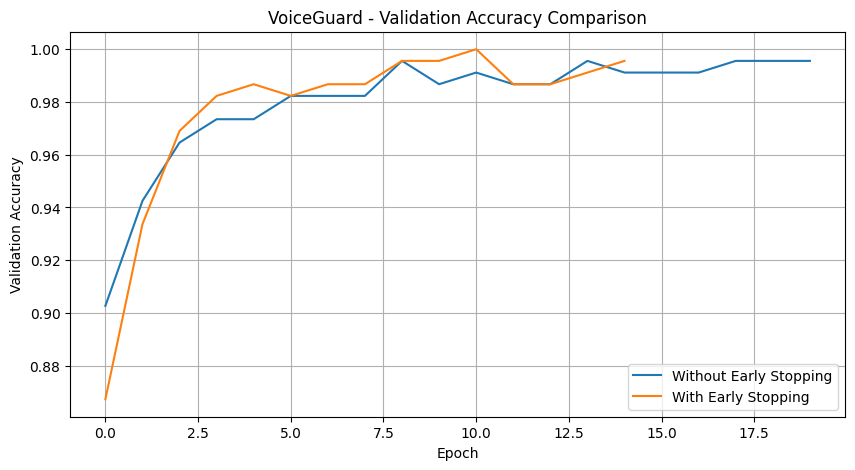

In [30]:
plt.figure(figsize=(10, 5))

plt.plot(
    history_without_es.history["val_accuracy"],
    label="Without Early Stopping"
)

plt.plot(
    history_with_es.history["val_accuracy"],
    label="With Early Stopping"
)

plt.title("VoiceGuard - Validation Accuracy Comparison")
plt.xlabel("Epoch")
plt.ylabel("Validation Accuracy")
plt.legend()
plt.grid(True)
plt.show()

In [31]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score
)

def evaluate_model(model, model_name):

    probabilities = model.predict(
        X_test,
        verbose=0
    ).ravel()

    predictions = (
        probabilities >= 0.5
    ).astype(int)

    return {
        "Model": model_name,
        "Accuracy": accuracy_score(y_test, predictions),
        "Precision": precision_score(y_test, predictions),
        "Recall": recall_score(y_test, predictions),
        "F1 Score": f1_score(y_test, predictions),
        "ROC-AUC": roc_auc_score(y_test, probabilities)
    }


without_es_results = evaluate_model(
    model_without_es,
    "Without Early Stopping"
)

with_es_results = evaluate_model(
    model_with_es,
    "With Early Stopping"
)

early_stopping_comparison = pd.DataFrame([
    without_es_results,
    with_es_results
])

print("=" * 70)
print("VOICEGUARD - EARLY STOPPING COMPARISON")
print("=" * 70)

display(
    early_stopping_comparison.style.format({
        "Accuracy": "{:.4f}",
        "Precision": "{:.4f}",
        "Recall": "{:.4f}",
        "F1 Score": "{:.4f}",
        "ROC-AUC": "{:.4f}"
    })
)

VOICEGUARD - EARLY STOPPING COMPARISON


,Model,Accuracy,Precision,Recall,F1 Score,ROC-AUC
0,Without Early Stopping,0.9956,1.0000,0.9912,0.9956,0.9999
1,With Early Stopping,0.9956,1.0000,0.9912,0.9956,1.0000


In [32]:
epoch_comparison = pd.DataFrame([
    {
        "Model": "Without Early Stopping",
        "Epochs Trained": len(
            history_without_es.history["loss"]
        ),
        "Best Validation Loss": min(
            history_without_es.history["val_loss"]
        )
    },
    {
        "Model": "With Early Stopping",
        "Epochs Trained": len(
            history_with_es.history["loss"]
        ),
        "Best Validation Loss": min(
            history_with_es.history["val_loss"]
        )
    }
])

print("=" * 70)
print("TRAINING EPOCH COMPARISON")
print("=" * 70)

display(
    epoch_comparison.style.format({
        "Best Validation Loss": "{:.4f}"
    })
)

TRAINING EPOCH COMPARISON


,Model,Epochs Trained,Best Validation Loss
0,Without Early Stopping,20,0.0106
1,With Early Stopping,15,0.0091
